# <span style="color:darkblue"> Lecture 15: Classification Metrics </span>

<font size = "5">

In this lecture we will learn more about Support <br>
Vector Machines (SVM). We will start the class with a short video:

 https://www.youtube.com/watch?v=_YPScrckx28

 https://www.youtube.com/watch?v=Q7vT0--5VII

 <font size = "5">

 In this lecture we will emphasize:
 - A new method SVM
 - Importance of scaling data
 - How to obtain performance metrics
 - How to tune parameters

# <span style="color:darkblue"> I. Setup Working Environment </span>


<font size = "5">

We will be using the API of the University of California <br>
Irving Machine Learning Repository

In Windows (Anaconda Prompt) or Mac (Terminal) type:

``` pip install ucimlrepo ```

https://archive.ics.uci.edu

In [1]:
# Import the package for the University of California Irvine API
from ucimlrepo import fetch_ucirepo 

# Import SK-Learn library for machine learning functions
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate
from sklearn import preprocessing
from sklearn.metrics import get_scorer_names


# Import standard data analysis packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# <span style="color:darkblue"> II. Data </span>

<font size = "5">

Online Shoppers Purchasing Intention Dataset (OSHPID)

- This dataset contains information about user sessions
- It contains features data about user behavior 
while <br> navigating website
- The goal is to predict whether the customer will purchase or not

https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset


In [2]:
# Fetch online data from the UC Irvine Machine Learning Repository API
online_shopping= fetch_ucirepo(id=468) 

# Extract
X = online_shopping.data.features
# Drop columns that contain non-numeric values
X = X.drop(columns = ["Month","VisitorType"])

# Extract label data
y = online_shopping.data.targets["Revenue"]


<font size = "5">

Total size of dataset

In [3]:
# Compute total numbers or rows
print(len(y))
print(len(X))

12330
12330


<font size = "5">

Extract column names

- Check separately in VS-Code Data Viewer

In [4]:
dataset_names = pd.DataFrame(X.columns)

<font size = "5">

Obtain table of proportions for outcome

- 0 if the customer did not purchase product
- 1 if the customer purchase the product

In [5]:
# Compute frequency table for label
table_y = pd.crosstab(y,"Purchased ?") / len(y)
display(table_y)

col_0,Purchased ?
Revenue,
False,0.845255
True,0.154745


<font size = "5">

Obtain Basic Descriptive Statistics of features

In [6]:
# Compute table of descriptive statistics for features
display(X.describe())

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


<font size = "5">

Split into training and test data

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y , 
                                   random_state=104,  
                                   test_size=0.25,  
                                   shuffle=True) 

<font size = "5">

For many ML problems it is useful to scale the data

<font size = "3">

- Preprocessing ensures that the data has mean zero and unit variance
- A lot of things related to sc-learn use a function structure
    -  You start by defining a "scaler" function which computes <br>
    the mean and variance.
    - Then the "scaler" function is applied to the corresponding dataset
    - It is important to compute a separate scalar for the training <br>
    and test data to avoid "contaminating" the data

In [8]:
# The first step is to produce a "scaler" function
scaler_train = preprocessing.StandardScaler().fit(X_train)
scaler_test  = preprocessing.StandardScaler().fit(X_test)

# Apply scaler function
X_train_scale = scaler_train.transform(X_train)
X_test_scale  = scaler_test.transform(X_test)

# <span style="color:darkblue"> III. Support Vector Machinees (SVMs) </span>

<font size = "5">

One of the most popular methods of classifcation are SVMs


<font size = "5">

https://scikit-learn.org/stable/modules/svm.html#svm-classification
https://en.wikipedia.org/wiki/Support_vector_machine


<font size = "3">

- The default regularization parameter is $C = 1$
- The default kernel curvature parameter is  $gamma = 1/(\# features)$


In [9]:
svm = SVC()
svm.fit(X_train_scale, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [10]:
X_train

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Weekend
7645,4,23.533333,0,0.0,10,118.000000,0.011111,0.066667,0.000000,0.0,2,2,2,3,True
141,0,0.000000,0,0.0,9,272.500000,0.000000,0.011852,0.000000,0.2,1,1,6,3,False
6801,1,0.000000,0,0.0,1,74.600000,0.100000,0.100000,0.000000,0.0,3,2,1,4,False
367,1,11.888889,0,0.0,111,3510.879903,0.000098,0.009438,12.016565,0.0,3,2,5,2,False
5815,16,391.683333,0,0.0,24,443.750000,0.000000,0.006452,0.000000,0.0,2,10,7,3,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6310,9,103.933333,0,0.0,16,172.133333,0.012000,0.049000,0.000000,0.0,1,1,1,2,False
8846,0,0.000000,3,1830.5,81,5000.739116,0.003294,0.020433,0.000000,0.0,2,2,3,2,True
729,0,0.000000,0,0.0,15,1148.000000,0.014286,0.050000,0.000000,0.0,3,2,1,3,False
5825,2,15.200000,0,0.0,22,244.200000,0.027273,0.063636,0.000000,0.0,2,2,7,1,True


<font size = "5">

Out-of-sample predictions

In [11]:
predictions = svm.predict(X_test_scale)


<font size = "5">

Confusion Matrix with SK-Learn


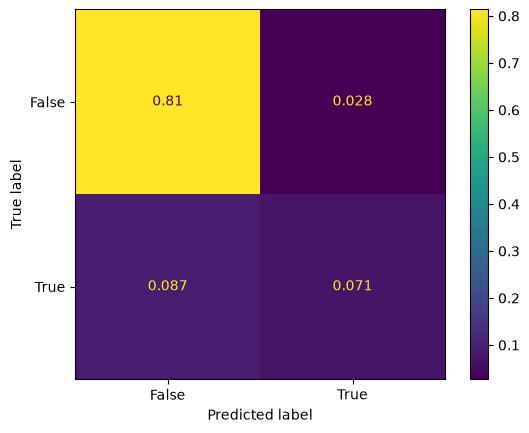

In [12]:
# Compute confusion matrix
cm = confusion_matrix(y_test, predictions, labels=svm.classes_) / len(y_test)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=svm.classes_)
disp.plot()
plt.show()

<font size = "5">

Try it yourself!

<font size = "3">

- What if you do not scale the features?
- Compute the confusion matrix for the SVM model without rescaling

Note:
- Often variables have very different scales
- Machine learning models such as SVM use notions of proximity 
- With heterogeneous variances, certain features will end up getting more
weight 
- Standardization helps puts the variables on equal footing

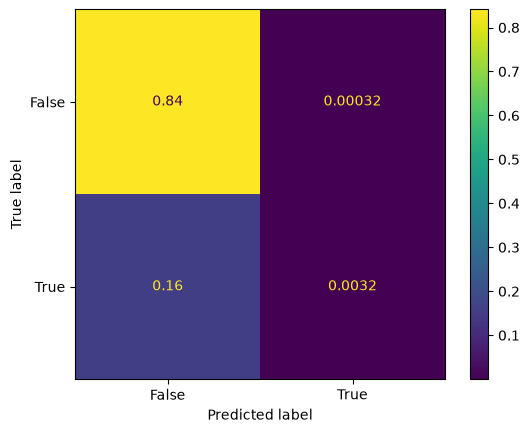

In [14]:
# Write your own code

svm = SVC()
svm.fit(X_train, y_train)

predictions_noscale = svm.predict(X_test)

# Compute confusion matrix
cm_noscale = confusion_matrix(y_test, predictions_noscale, labels=svm.classes_) / len(y_test)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm_noscale,
                               display_labels=svm.classes_)
disp.plot()
plt.show()


# <span style="color:darkblue"> III. Performance and Decision Thresholds </span>

<font size = "5">

There are many possible performance metrics

(see textbook for more details)

In [15]:
list_scorers =  pd.DataFrame(get_scorer_names())
list_scorers

,0
0,accuracy
1,adjusted_mutual_info_score
2,adjusted_rand_score
3,average_precision
4,balanced_accuracy
5,completeness_score
6,d2_absolute_error_score
7,d2_brier_score
8,d2_log_loss_score
9,explained_variance


<font size = "5">

Obtain some of these metrics via cross-validation

- This usually takes a while to compute

In [18]:
# Scoring sets the variables that you want to compute

res = cross_validate(SVC(), X_train_scale, y_train,
                     scoring=["accuracy", "roc_auc", "recall_macro"],
                     return_train_score=False, cv=5)
display(pd.DataFrame(res))

,fit_time,score_time,test_accuracy,test_roc_auc,test_recall_macro
0,0.909840,0.496040,0.886486,0.846869,0.719641
1,0.841848,0.492480,0.892432,0.862575,0.721712
2,0.536595,0.554911,0.903191,0.854618,0.732961
3,0.657575,0.446686,0.898864,0.873559,0.725535
4,0.632267,0.523394,0.894538,0.826146,0.727303


<font size = "5">

Summarize results across folds

In [19]:
pd.DataFrame(res).mean()

fit_time             0.715625
score_time           0.502702
test_accuracy        0.895102
test_roc_auc         0.852754
test_recall_macro    0.725430
dtype: float64

<font size ="5">

Try it yourself!

Try obtaining other performance metrics
 

In [20]:
# Write your own code

res2 = cross_validate(SVC(), X_train_scale, y_train,
                      scoring=["precision", "recall", "f1",
                               "balanced_accuracy", "average_precision"],
                      cv=5)
pd.DataFrame(res2).mean()


fit_time                  0.602322
score_time                0.551616
test_precision            0.747448
test_recall               0.480625
test_f1                   0.584680
test_balanced_accuracy    0.725430
test_average_precision    0.661381
dtype: float64

# <span style="color:darkblue"> IV. Tuning by Cross Validation </span>


<font size = "5">

Manually create a grid of values for tuning

<font size = "3">

- Initially we will run this with a single training-test pair
- For computational ease we just try two parameters <br>
on the grid, but in a real application we may want more

In [21]:
k_features = X.shape[1]
k_features

15

In [22]:
k_features = X.shape[1]

best_score = 0

for gamma in [0.1/(k_features), 1/(k_features)]:   
    for C in [0.1, 1]:
        # Add a message to know the progress of the algorithm
        print("Evaluating - gamma: "+str(gamma)+"  - C: "+str(C))
        # for each combination of parameters, train an SVC
        svm = SVC(gamma=gamma, C=C)
        svm.fit(X_train_scale, y_train)
        # evaluate the SVC on the test set
        score = svm.score(X_test, y_test)
        # if we got a better score, store the score and parameters
        if score > best_score:
            best_score = score
            best_parameters = {'C': C, 'gamma': gamma}

print(best_parameters)

Evaluating - gamma: 0.006666666666666667  - C: 0.1


/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


Evaluating - gamma: 0.006666666666666667  - C: 1


/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


Evaluating - gamma: 0.06666666666666667  - C: 0.1


/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


Evaluating - gamma: 0.06666666666666667  - C: 1


/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


{'C': 0.1, 'gamma': 0.006666666666666667}


<font size = "5">

Estimate optimal model on all data

In [23]:

# rebuild a model on the combined training and validation set
# **best_parameters enters the dictionary format

svm = SVC(**best_parameters)
svm.fit(X_train_scale, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.1
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.006666666666666667
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


<font size ="5">

Obtain confusion matrix

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


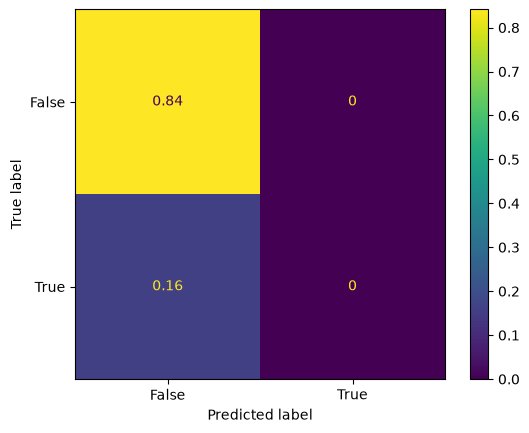

In [24]:
# Obtain predictions
predictions = svm.predict(X_test)

# Compute confusion matrix
cm = confusion_matrix(y_test, predictions, labels=svm.classes_) / len(y_test)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=svm.classes_)
disp.plot()
plt.show()

<font size = "5">

Create a grid of parameters

In [25]:
param_grid = {'C': [ 0.01, 0.1],
              'gamma': [0.01/(k_features), 0.1/(k_features)]}
print("Parameter grid:\n{}".format(param_grid))

Parameter grid:
{'C': [0.01, 0.1], 'gamma': [0.0006666666666666666, 0.006666666666666667]}


<font size = "5">

Create configuration object for grid <br>
usng K-Fold cross-valdaton

- We set the number of folds "cv" to 2 for speed <br>
but in real applications you may want to have a larger <br>
number such as 5 so that the training set has more <br>
observations.

In [28]:
grid_search = GridSearchCV(SVC(), param_grid, cv=2,
                          return_train_score=True,
                          n_jobs = -1)

In [29]:
# Execute grd search

grid_search.fit(X_train_scale, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1], 'gamma': [0.0006666666666666666, 0.006666666666666667]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",2
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scor

<font size = "5">

Try it yourself!

- Create a grid for random forests on this dataset, <br>
varying the numbers of forests, i.e. the  argument <br>
```n_estimators``` in the random forest classifier.
- To keep the code from taking too long, <br>
try with 10 trees and 50 trees.

In [ ]:
# Write your own code

from sklearn.ensemble import RandomForestClassifier

# Grid of values for the number of trees
param_grid_rf = {'n_estimators': [10, 50]}

# Grid search with 2-fold cross-validation (same setup as the SVM above)
grid_search_rf = GridSearchCV(RandomForestClassifier(random_state=0), param_grid_rf,
                              cv=2, return_train_score=True, n_jobs=-1)

# Execute grid search
grid_search_rf.fit(X_train_scale, y_train)

# Results
print("Best parameters: {}".format(grid_search_rf.best_params_))
print("Best cross-validation score: {:.3f}".format(grid_search_rf.best_score_))
print("Test set score: {:.3f}".format(grid_search_rf.score(X_test_scale, y_test)))

display(pd.DataFrame(grid_search_rf.cv_results_)[["param_n_estimators", "mean_train_score", "mean_test_score"]])



